# 05 예측: 추천 3곳의 다음 1년 매출과 손님

`04`에서 고른 3곳(공릉역, 대치역, 방이역)의 **다음 4개 분기(2026년 3분기 ~ 2027년 2분기) 월평균 매출과 결제 건수**를 예측한다.

**방법**

- 상권 하나에는 22개 분기밖에 없어서 한 상권만으로 모델을 만들면 불안정하다. 그래서 **22개 분기 모두 매출이 공개된 916개 상권을 함께 학습**한다(추천 3곳 포함).
- **목표 변수**: 1년 전 같은 분기 대비 로그 변화(`log(값) − log(1년 전 같은 분기 값)`). 계절 효과를 목표에서 미리 빼 두는 셈이다. 예측값 0은 "작년 같은 분기와 같다"는 뜻이다.
- **입력 변수**(예측 시점에 알 수 있는 값만): 최근 전년 동기 변화(1분기 전·2분기 전), 최근 4개 분기 평균 전년 동기 변화, 점포 수의 전년 동기 변화, 점포당 값의 수준, 몇 분기 뒤를 맞히는지(1~4), 맞히는 분기(1~4분기), 상권 유형.
- **모델**: 그래디언트 부스팅(`HistGradientBoostingRegressor`)과 릿지 회귀. 몇 분기 뒤인지를 입력으로 넣어 한 모델이 1~4분기 뒤를 모두 맞힌다.
- **비교 기준**: ① 계절 단순 예측(작년 같은 분기와 같다) ② 단순 예측 + 최근 1년 성장률 ③ 상권별 Holt-Winters(가법 추세·계절).
- **검증**: 시점을 고정해 미래를 숨기는 백테스트. 2024년 2분기까지만 보고 다음 4개 분기를 맞히기(검증), 2025년 2분기까지만 보고 다음 4개 분기를 맞히기(시험). 지표는 WAPE(전체 오차 합 ÷ 전체 실제값 합)와 상권별 오차율의 중앙값.
- **예측 범위**: 시험 백테스트의 오차 분포(몇 분기 뒤인지별 10%·90% 분위)로 80% 범위를 만든다.

금액과 건수는 그 분기의 월평균이다.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sqlalchemy import URL, create_engine
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore", module="statsmodels")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

load_dotenv("../.env", override=True)
engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.environ["PGUSER"],
    password=os.environ["PGPASSWORD"],
    host=os.environ["PGHOST"],
    port=int(os.environ["PGPORT"]),
    database=os.environ["PGDATABASE"],
))
OUT = Path("../data/processed")

원자료 = pd.read_sql("""
SELECT m."기준_년분기_코드", m."상권_코드", m."상권_코드_명", m."상권_구분_코드_명",
       m."당월_매출_금액" AS 매출, m."당월_매출_건수" AS 건수, p."전체_점포_수" AS 점포
FROM "커피_매출" m JOIN "커피_점포" p USING ("기준_년분기_코드", "상권_코드")
""", engine)
분기 = sorted(원자료["기준_년분기_코드"].unique())
이름 = 원자료.drop_duplicates("상권_코드").set_index("상권_코드")["상권_코드_명"]
유형 = 원자료.drop_duplicates("상권_코드").set_index("상권_코드")["상권_구분_코드_명"]
점포_표 = 원자료.pivot(index="상권_코드", columns="기준_년분기_코드", values="점포")

순위 = pd.read_csv(OUT / "추천_순위.csv", dtype={"상권_코드": str}).set_index("상권_코드")
추천 = list(순위[순위["추천"]].sort_values("순위").index)
print("추천 3곳:", [이름[c] for c in 추천])

추천 3곳: ['공릉역', '대치역', '방이역']


## 1. 학습 데이터

In [2]:
표 = {k: 원자료.pivot(index="상권_코드", columns="기준_년분기_코드", values=k).dropna() for k in ["건수", "매출"]}
for k, v in 표.items():
    print(k, "| 22개 분기 모두 있는 상권", len(v), "| 추천 3곳 포함", all(c in v.index for c in 추천))

건수 | 22개 분기 모두 있는 상권 916 | 추천 3곳 포함 True
매출 | 22개 분기 모두 있는 상권 916 | 추천 3곳 포함 True


## 2. 입력 변수와 목표 변수

예측 시점 `t`에서 `h`분기 뒤(1~4)를 맞힌다. `h`가 4 이하이므로 "1년 전 같은 분기 값"은 예측 시점에 이미 알고 있다.

In [3]:
def 만들기(값_표, 시점들, 목표_포함=True):
    """시점마다 1~4분기 뒤를 맞히는 행을 만든다."""
    L = np.log(값_표)
    LS = np.log(점포_표.reindex(값_표.index)[분기].clip(lower=1))
    행 = []
    for t in 시점들:
        i = 분기.index(t)
        공통 = pd.DataFrame({
            "변화_1": L[분기[i]] - L[분기[i - 4]],
            "변화_2": L[분기[i - 1]] - L[분기[i - 5]],
            "변화_4평균": (L[분기[i - 3:i + 1]].sum(axis=1) - L[분기[i - 7:i - 3]].sum(axis=1)) / 4,
            "점포_변화": LS[분기[i]] - LS[분기[i - 4]],
            "점포당_수준": L[분기[i]] - LS[분기[i]],
        })
        for h in (1, 2, 3, 4):
            df = 공통.copy()
            df["h"] = h
            df["맞힐_분기"] = (int(t[-1]) - 1 + h) % 4 + 1
            df["기준"] = L[분기[i + h - 4]]  # 1년 전 같은 분기(로그)
            df["시점"] = t
            df["목표_분기"] = 분기[i + h] if i + h < len(분기) else None
            df["y"] = L[분기[i + h]] - df["기준"] if (목표_포함 and i + h < len(분기)) else np.nan
            df["유형"] = 유형.reindex(df.index).values
            행.append(df)
    return pd.concat(행).rename_axis("상권_코드").reset_index()


def 입력(df):
    x = df[["변화_1", "변화_2", "변화_4평균", "점포_변화", "점포당_수준", "h"]].copy()
    for k in (1, 2, 3, 4):
        x[f"분기_{k}"] = (df["맞힐_분기"] == k).astype(int)
    for u in ["골목상권", "발달상권", "전통시장", "관광특구"]:
        x[u] = (df["유형"] == u).astype(int)
    return x


def 모델들():
    return {
        "릿지": Ridge(alpha=1.0),
        "그래디언트 부스팅": HistGradientBoostingRegressor(
            max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=40,
            l2_regularization=1.0, random_state=0),
    }


시점들 = 분기[7:]  # 변화_4평균에 8개 분기가 필요하다
print("예측 시점:", 시점들[0], "~", 시점들[-1])

예측 시점: 20224 ~ 20262


## 3. 백테스트

예측 시점까지의 자료로만 학습(목표 분기가 예측 시점 이전인 행)하고, 다음 4개 분기를 맞힌다.

In [4]:
def 홀트_윈터스(값_표, 시점):
    i = 분기.index(시점)
    결과 = {}
    for 코드 in 값_표.index:
        y = np.log(값_표.loc[코드, 분기[:i + 1]].to_numpy(dtype=float))
        try:
            결과[코드] = ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="add", seasonal_periods=4).fit().forecast(4)
        except Exception:
            결과[코드] = np.repeat(y[-1], 4)
    return 결과


def 백테스트(값_표, 시점):
    전체 = 만들기(값_표, 시점들)
    학습 = 전체[전체["목표_분기"].notna() & (전체["목표_분기"] <= 시점)]
    시험 = 전체[(전체["시점"] == 시점) & 전체["목표_분기"].notna()].copy()
    예측 = {
        "계절 단순 예측": 시험["기준"],
        "단순 예측 + 최근 성장": 시험["기준"] + 시험["변화_4평균"],
    }
    for 이름_, 모델 in 모델들().items():
        모델.fit(입력(학습), 학습["y"])
        예측[이름_] = 시험["기준"] + 모델.predict(입력(시험))
    hw = 홀트_윈터스(값_표, 시점)
    예측["Holt-Winters"] = pd.Series([hw[c][h - 1] for c, h in zip(시험["상권_코드"], 시험["h"])], index=시험.index)
    실제 = np.exp(시험["기준"] + 시험["y"])
    행 = []
    for 방법, 로그값 in 예측.items():
        오차 = (np.exp(로그값) - 실제).abs()
        행.append((방법, 오차.sum() / 실제.sum() * 100, (오차 / 실제).median() * 100,
                   (오차 / 실제)[시험["상권_코드"].isin(추천)].mean() * 100))
    성적 = pd.DataFrame(행, columns=["방법", "WAPE(%)", "상권별 오차율 중앙값(%)", "추천 3곳 평균 오차율(%)"]).set_index("방법")
    시험["로그_오차"] = 시험["기준"] + 시험["y"] - 예측["그래디언트 부스팅"]
    return 성적, 시험


성적 = {}
시험_오차 = {}
for k in ["건수", "매출"]:
    for 시점, 구분 in [("20242", "검증"), ("20252", "시험")]:
        성적[(k, 구분)], 결과 = 백테스트(표[k], 시점)
        if 구분 == "시험":
            시험_오차[k] = 결과
pd.concat(성적, axis=1).round(1)

건수                                                        \
                   검증                                     시험                  
              WAPE(%) 상권별 오차율 중앙값(%) 추천 3곳 평균 오차율(%) WAPE(%) 상권별 오차율 중앙값(%)   
방법                                                                            
계절 단순 예측         13.4           14.5            13.8    13.2           13.5   
단순 예측 + 최근 성장    17.2           17.9            32.8    21.2           16.7   
릿지               14.6           15.3            14.9    12.3           12.9   
그래디언트 부스팅        12.5           13.2            17.5    11.5           11.8   
Holt-Winters     15.5           15.9            11.6    14.0           13.7   

                                   매출                                         \
                                   검증                                     시험   
              추천 3곳 평균 오차율(%) WAPE(%) 상권별 오차율 중앙값(%) 추천 3곳 평균 오차율(%) WAPE(%)   
방법                                                                             
계절 단순 예측                 23.0    12.9           14.4            16.1    14.0   
단순 예측 + 최근 성장            29.9    17.1           18.5            28.2    18.3   
릿지                       23.0    13.4           15.0            13.1    13.6   
그래디언트 부스팅                24.1    12.0           13.7            13.8    13.0   
Holt-Winters             19.2    14.5           16.0            13.6    14.0   

                                              
                                              
              상권별 오차율 중앙값(%) 추천 3곳 평균 오차율(%)  
방법                                            
계절 단순 예측                13.9            23.6  
단순 예측 + 최근 성장           17.9            35.9  
릿지                      14.2            24.9  
그래디언트 부스팅               13.5            25.9  
Holt-Winters            14.8            22.8

**읽는 법**: 그래디언트 부스팅이 검증과 시험 모두에서 계절 단순 예측보다 오차가 작으면 쓸 만하다. 차이가 작다면 "작년 같은 분기와 비슷할 것"이 대부분의 정보라는 뜻이다. 추천 3곳의 오차가 전체보다 큰 것은, 이 3곳이 **최근에 손님이 크게 늘어서 뽑힌 상권**이라 과거 패턴으로는 그 증가를 미리 알기 어렵기 때문이다.

## 4. 최종 예측

모든 자료(목표 분기 ≤ 2026년 2분기)로 다시 학습하고, 2026년 2분기 시점에서 다음 4개 분기를 예측한다. 80% 범위는 시험 백테스트에서 그래디언트 부스팅의 로그 오차 10%·90% 분위(몇 분기 뒤인지별)를 더해 만든다.

In [5]:
마지막 = 분기[-1]
미래_분기 = ["20263", "20264", "20271", "20272"]
예측_행 = []
for k in ["건수", "매출"]:
    전체 = 만들기(표[k], 시점들)
    학습 = 전체[전체["목표_분기"].notna()]
    모델 = 모델들()["그래디언트 부스팅"].fit(입력(학습), 학습["y"])
    미래 = 만들기(표[k].loc[추천], [마지막], 목표_포함=False)
    미래["예측"] = np.exp(미래["기준"] + 모델.predict(입력(미래)))
    분위 = 시험_오차[k].groupby("h")["로그_오차"].quantile([0.1, 0.9]).unstack()
    미래["하한_80"] = 미래["예측"] * np.exp(미래["h"].map(분위[0.1]))
    미래["상한_80"] = 미래["예측"] * np.exp(미래["h"].map(분위[0.9]))
    미래["대상"] = k
    미래["분기"] = [미래_분기[h - 1] for h in 미래["h"]]
    예측_행.append(미래[["상권_코드", "대상", "분기", "h", "예측", "하한_80", "상한_80"]])
예측 = pd.concat(예측_행)
예측["상권"] = 예측["상권_코드"].map(이름)
보기 = 예측.copy()
보기.loc[보기["대상"] == "건수", ["예측", "하한_80", "상한_80"]] /= 1e4
보기.loc[보기["대상"] == "매출", ["예측", "하한_80", "상한_80"]] /= 1e8
print("건수는 만 건, 매출은 억 원(모두 월평균)")
보기.pivot_table(index=["상권", "대상"], columns="분기", values="예측").round(1)

건수는 만 건, 매출은 억 원(모두 월평균)


분기      20263  20264  20271  20272
상권  대상                            
공릉역 건수   21.8   17.6   16.8   17.9
    매출   17.5   15.3   13.6   13.2
대치역 건수   23.0   16.6   16.6   19.6
    매출   10.9    7.6    8.1    9.7
방이역 건수   52.5   41.2   39.2   46.1
    매출   21.9   16.4   16.3   18.6

In [6]:
# 1년 합계로 요약: 다음 4개 분기 대 최근 4개 분기
최근4 = 분기[-4:]
요약 = []
for 코드 in 추천:
    for k in ["건수", "매출"]:
        p = 예측[(예측["상권_코드"] == 코드) & (예측["대상"] == k)]
        최근_합 = 표[k].loc[코드, 최근4].sum()
        점포_최근 = 점포_표.loc[코드, 최근4].mean()
        요약.append({
            "상권": 이름[코드], "대상": k,
            "최근 1년 월평균": 최근_합 / 4,
            "다음 1년 월평균(예측)": p["예측"].sum() / 4,
            "예측 증가율(%)": (p["예측"].sum() / 최근_합 - 1) * 100,
            "80% 범위 하한(%)": (p["하한_80"].sum() / 최근_합 - 1) * 100,
            "80% 범위 상한(%)": (p["상한_80"].sum() / 최근_합 - 1) * 100,
            "점포당 다음 1년 월평균(점포 수 그대로일 때)": p["예측"].sum() / 4 / 점포_최근,
        })
요약 = pd.DataFrame(요약)
요약.round(1)

,상권,대상,최근 1년 월평균,다음 1년 월평균(예측),예측 증가율(%),80% 범위 하한(%),80% 범위 상한(%),점포당 다음 1년 월평균(점포 수 그대로일 때)
0,공릉역,건수,1.779468e+05,1.850703e+05,4.0,-18.9,50.0,11750.5
1,공릉역,매출,1.953984e+09,1.488198e+09,-23.8,-41.3,14.4,94488740.9
2,대치역,건수,1.914658e+05,1.896212e+05,-1.0,-22.8,42.7,16855.2
3,대치역,매출,9.172550e+08,9.068812e+08,-1.1,-23.9,48.5,80611664.0
4,방이역,건수,4.376675e+05,4.474455e+05,2.2,-20.4,47.4,26713.2
5,방이역,매출,1.833388e+09,1.828369e+09,-0.3,-23.2,49.8,109156366.4


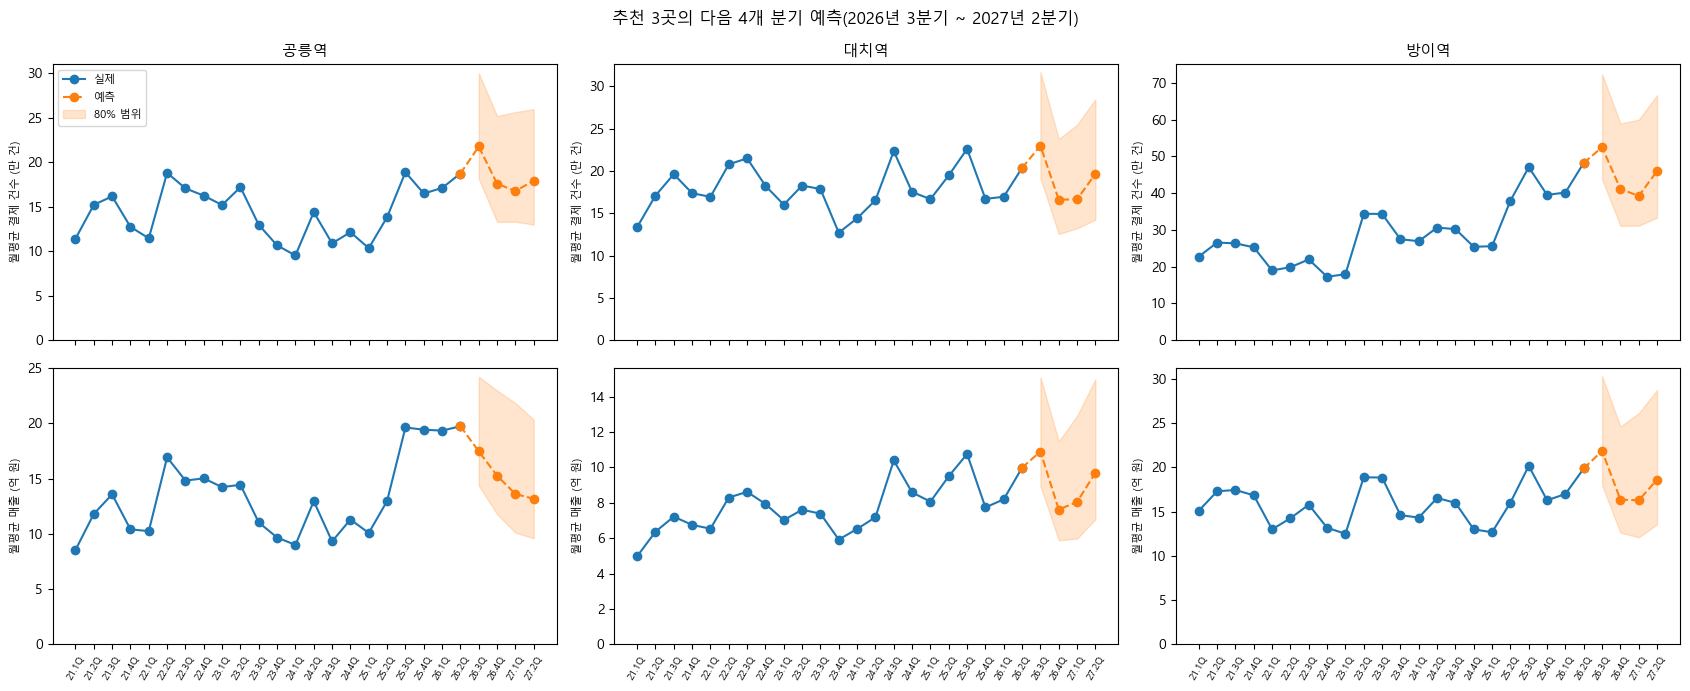

In [7]:
그림_분기 = 분기 + 미래_분기
x_이름 = [f"{q[2:4]}.{q[4]}Q" for q in 그림_분기]
fig, axes = plt.subplots(2, 3, figsize=(17, 7), sharex=True)
for 열, 코드 in enumerate(추천):
    for 행, (k, 단위, 나눔) in enumerate([("건수", "결제 건수 (만 건)", 1e4), ("매출", "매출 (억 원)", 1e8)]):
        ax = axes[행, 열]
        ax.plot(x_이름[:len(분기)], 표[k].loc[코드, 분기] / 나눔, marker="o", color="tab:blue", label="실제")
        p = 예측[(예측["상권_코드"] == 코드) & (예측["대상"] == k)].sort_values("h")
        ax.plot(x_이름[len(분기) - 1:], np.r_[표[k].loc[코드, 마지막], p["예측"]] / 나눔,
                marker="o", linestyle="--", color="tab:orange", label="예측")
        ax.fill_between(x_이름[len(분기):], p["하한_80"] / 나눔, p["상한_80"] / 나눔, color="tab:orange", alpha=0.2, label="80% 범위")
        ax.set_ylim(bottom=0)
        ax.set_ylabel(f"월평균 {단위}", fontsize=8)
        if 행 == 0:
            ax.set_title(이름[코드], fontsize=11)
        ax.tick_params(axis="x", labelrotation=60, labelsize=7)
axes[0, 0].legend(fontsize=8)
plt.suptitle("추천 3곳의 다음 4개 분기 예측(2026년 3분기 ~ 2027년 2분기)")
plt.tight_layout()
plt.show()

In [8]:
예측.to_csv(OUT / "예측_결과.csv", index=False, encoding="utf-8")
요약.round(2).to_csv(OUT / "예측_요약.csv", index=False, encoding="utf-8")
pd.concat(성적, axis=1).round(2).to_csv(OUT / "예측_백테스트.csv", encoding="utf-8")
print("저장 완료")

저장 완료


## 5. 해석

**모델 성능**
- 916개 상권 전체로 보면 그래디언트 부스팅이 검증과 시험 모두에서 가장 정확했다. 계절 단순 예측보다 WAPE가 건수는 13.4 → 12.5%(검증), 13.2 → 11.5%(시험), 매출은 12.9 → 12.0%, 14.0 → 13.0%로 낮다. 하나 짚을 점은 이 모델이 시험 결과까지 보고 고른 것이 아니라 검증과 시험에서 모두 1위였다는 것이다.
- 다만 개선 폭은 1~2%p다. 상권 매출과 손님은 "작년 같은 분기와 비슷하다"가 대부분의 정보이고, 모델은 거기에 최근 흐름을 조금 더 반영하는 정도다.
- **추천 3곳만 보면** 모델의 오차(시험: 건수 24%, 매출 26%)가 계절 단순 예측(23%, 24%)보다 오히려 조금 크다. 이 3곳은 최근 손님이 크게 늘어서 뽑힌 상권이라 과거 패턴으로 그 증가를 미리 알 수 없다. 80% 범위도 대략 −20% ~ +50%로 넓다.

**예측 내용(다음 4개 분기, 최근 4개 분기 대비)**
- **손님(결제 건수)**: 공릉역 +4.0%, 대치역 −1.0%, 방이역 +2.2%. 세 곳 모두 지금 수준을 유지한다고 본다. 지난 2년처럼 더 크게 늘어난다는 예측은 아니다.
- **매출**: 대치역 −1.1%, 방이역 −0.3%로 그대로다. **공릉역은 −23.8%**다. 공릉역은 2025년 3분기에 매출이 한 분기 만에 크게 뛰었고 건당 금액도 2년 사이 22% 올랐다. 점포당 월 매출이 분석 대상 중 최상위권이라 모델이 일부 되돌아갈 것으로 본 것이다. 손님 예측(+4%)과 매출 예측(−24%)이 엇갈리므로, 공릉역은 "손님은 유지되지만 손님 한 명당 지출이 예전 수준으로 내려갈 수 있다"는 위험으로 읽는다.

**대표님께**
- "세 곳 모두 지난 2년 동안 늘어난 손님이 앞으로 1년 동안 빠지지 않고 유지될 것으로 보입니다. 더 늘어난다는 예측은 아닙니다."
- "공릉역은 손님은 유지되지만 매출이 줄 수 있다는 신호가 있어, 객단가를 보수적으로 잡고 계획하시는 게 좋습니다."
- "상권 하나의 1년 뒤 숫자는 ±20~50% 범위로 흔들리므로, 이 예측은 '방향'을 보는 자료이고 매출 약속은 아닙니다."
